Cài đặt môi trường

In [2]:
import os, json, time, math
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy import stats
from tqdm.auto import tqdm

# Jupyter Lab chạy kernel với thư mục hiện hành = thư mục chứa notebook (ics-ai/notebooks)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
# Phải trùng với WORK_DIR ở notebook 01–03
WORK_DIR = Path(os.environ.get('CIC_MODBUS_WORK', PROJECT_ROOT / 'Modbus-Work')).resolve()
PROC = WORK_DIR / 'processed'
RUNS = WORK_DIR / 'runs'
RUNS.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else '')
if DEVICE.type == 'cpu':
    print('⚠ Không thấy GPU: vẫn chạy được nhưng chậm hơn nhiều. Kiểm tra lại bản PyTorch CUDA.')

torch 2.11.0+cu128 | device: cuda NVIDIA GeForce RTX 3050 Laptop GPU


Nạp dữ liệu 

In [3]:
BYTES  = np.load(PROC / 'bytes30.npy', mmap_mode='r')          # (N, 30) uint8
LABELS = np.load(PROC / 'labels.npy').astype(np.int64)          # (N,) 0 = Normal
META   = pd.read_parquet(PROC / 'meta.parquet', columns=['split', 'in_delay_window'])
APPROACHES = json.loads((PROC / 'approaches.json').read_text(encoding='utf-8'))
CMAP = json.loads((PROC / 'class_map.json').read_text(encoding='utf-8'))
CLASSES = CMAP['classes']
K_MC = len(CLASSES)
SPLIT = META['split'].astype(str).to_numpy()
DELAY = META['in_delay_window'].to_numpy().astype(bool)
IDX = {s: np.flatnonzero(SPLIT == s) for s in ['train', 'val', 'test']}
print(f"{len(LABELS):,} gói | split_mode = {CMAP.get('split_mode')!r} | {K_MC} lớp")

PAPER_T3 = {'Normal': (8_597_652, 1_074_707, 1_074_707), 'Brute force': (505_960, 63_245, 63_245),
            'Query flooding': (4_773, 597, 597), 'Replay': (1_425, 178, 179), 'Frame stacking': (1_068, 133, 134),
            'Payload injection': (290, 36, 37), 'Recon': (284, 35, 36), 'FDI': (42, 5, 6), 'Length manipulation': (20, 3, 3)}
tab = pd.crosstab(pd.Categorical.from_codes(LABELS, CLASSES), pd.Categorical(SPLIT, ['train', 'val', 'test']))
tab.index.name, tab.columns.name = 'label', 'split'
tab['paper (train/val/test)'] = tab.index.map(lambda c: '/'.join(f'{x:,}' for x in PAPER_T3.get(c, ())))
tab

11,390,143 gói | split_mode = 'random' | 9 lớp


split,train,val,test,paper (train/val/test)
label,,,,
Normal,8552596,1069075,1069074,"8,597,652/1,074,707/1,074,707"
Brute force,542053,67757,67756,"505,960/63,245/63,245"
Query flooding,8736,1092,1092,"4,773/597/597"
Replay,3775,472,471,"1,425/178/179"
Frame stacking,1157,145,144,"1,068/133/134"
Payload injection,1750,219,218,290/36/37
Recon,1601,200,200,284/35/36
FDI,43,5,5,42/5/6
Length manipulation,406,51,50,20/3/3


Tạo ảnh nhị phân ngay trên GPU

In [ ]:
SHIFTS = torch.arange(7, -1, -1, dtype=torch.uint8)

def bytes_to_images(b: torch.Tensor, approach: str) -> torch.Tensor:
    """(n, 30) uint8 -> (n, 1, H, W) float32 gồm 0/1 theo Table 1 của bài báo."""
    s, e = APPROACHES[approach]['bytes']
    h, w = APPROACHES[approach]['shape']
    bits = (b[:, s:e].unsqueeze(-1) >> SHIFTS.to(b.device)) & 1
    return bits.reshape(-1, 1, h, w).float()

_probe = np.array(BYTES[:1000])
for ap, a in APPROACHES.items():
    ref = np.unpackbits(_probe[:, a['bytes'][0]:a['bytes'][1]], axis=1).reshape(-1, *a['shape'])
    got = bytes_to_images(torch.from_numpy(_probe), ap)[:, 0].numpy()
    assert (ref == got).all(), ap
print('bytes_to_images khớp np.unpackbits cho cả 5 approach:', {k: tuple(v['shape']) for k, v in APPROACHES.items()})

In [ ]:
Chọn mẫu huấn luyện: Cap và trọng số lớp

In [5]:
EXCLUDE_DELAY = False

def targets(task: str, idx: np.ndarray) -> np.ndarray:
    y = LABELS[idx]
    return (y > 0).astype(np.int64) if task == 'binary' else y

def capped_indices(split: str, task: str, cap: int, seed: int) -> np.ndarray:
    """Tối đa `cap` mẫu mỗi lớp của `split`. Chỉ dùng cho train và val."""
    rng = np.random.default_rng(seed)
    idx = IDX[split]
    if EXCLUDE_DELAY:
        idx = idx[~DELAY[idx]]
    y = targets(task, idx)
    return np.sort(np.concatenate([rng.permutation(idx[y == c])[:cap] for c in np.unique(y)]))

def class_weights(y: np.ndarray, n_classes: int) -> torch.Tensor:
    """w_c = N / (K·N_c); K = số lớp có mặt, lớp vắng mặt nhận trọng số 0."""
    cnt = np.bincount(y, minlength=n_classes).astype(float)
    k = int((cnt > 0).sum())
    return torch.tensor(np.where(cnt > 0, len(y) / (k * np.maximum(cnt, 1)), 0.0), dtype=torch.float32)

for task, cap in [('multiclass', 5_000), ('binary', 50_000)]:
    tr = capped_indices('train', task, cap, seed=0)
    y = targets(task, tr)
    names = CLASSES if task == 'multiclass' else ['Normal', 'Attack']
    w = class_weights(y, len(names)).numpy()
    print(f'{task} (cap={cap:,}): {len(tr):,} mẫu train')
    print(pd.DataFrame({'n': np.bincount(y, minlength=len(names)), 'weight': w.round(3)}, index=names).T.to_string(), '\n')

multiclass (cap=5,000): 23,732 mẫu train
          Normal  Brute force  Query flooding    Replay  Frame stacking  Payload injection     Recon        FDI  Length manipulation
n       5000.000     5000.000        5000.000  3775.000        1157.000           1750.000  1601.000  43.000000              406.000
weight     0.527        0.527           0.527     0.699           2.279              1.507     1.647  61.323002                6.495 

binary (cap=50,000): 100,000 mẫu train
         Normal   Attack
n       50000.0  50000.0
weight      1.0      1.0 



In [ ]:
Kiến trúc CNN: Binary và Multiclass

In [6]:
BIN_KERNELS = {'1': (5, 2), '2': (5, 2), '2b': (5, 2), '3': (5, 1), '3b': (5, 2)}

class BinaryCNN(nn.Module):
    def __init__(self, h, w, k1, k2):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 1, k1), nn.Tanh(), nn.MaxPool2d(2, stride=2),
            nn.Conv2d(1, 1, k2), nn.Tanh(), nn.Flatten())
        with torch.no_grad():                       # tính kích thước flatten bằng một lần forward thử
            n = self.features(torch.zeros(1, 1, h, w)).shape[1]
        self.fc = nn.Linear(n, 2)

    def forward(self, x):
        return self.fc(self.features(x))

class MultiCNN(nn.Module):
    def __init__(self, h, w, n_classes, filters=32, act=nn.Sigmoid, batchnorm=False):
        super().__init__()
        bn = (lambda c: nn.BatchNorm2d(c)) if batchnorm else (lambda c: nn.Identity())
        self.features = nn.Sequential(
            nn.Conv2d(1, filters, 3, padding=1), bn(filters), act(), nn.MaxPool2d(2, stride=1),
            nn.Conv2d(filters, filters, 2), bn(filters), act(), nn.Flatten())
        with torch.no_grad():
            n = self.features(torch.zeros(1, 1, h, w)).shape[1]
        self.fc = nn.Linear(n, n_classes)

    def forward(self, x):
        return self.fc(self.features(x))

def make_model(task, approach, **kw):
    h, w = APPROACHES[approach]['shape']
    if task == 'binary':
        return BinaryCNN(h, w, *BIN_KERNELS[approach])
    return MultiCNN(h, w, K_MC, **kw)

n_params = lambda m: sum(p.numel() for p in m.parameters() if p.requires_grad)
PAPER_PARAMS = {'binary':     {'1': 51, '2': 63, '2b': 73, '3': 38, '3b': 39},
                'multiclass': {'1': 33_257, '2': 48_809, '2b': 56_873, '3': 14_825, '3b': 21_737}}
pt = pd.DataFrame([dict(task=t, approach=a, params=n_params(make_model(t, a)), paper=PAPER_PARAMS[t][a])
                   for t in PAPER_PARAMS for a in APPROACHES])
pt['match'] = pt.params == pt.paper
assert pt.match.all(), pt[~pt.match]
print(make_model('multiclass', '2b'))
pt.pivot(index='approach', columns='task', values=['params', 'paper'])

MultiCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): Identity()
    (2): Sigmoid()
    (3): MaxPool2d(kernel_size=2, stride=1, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 32, kernel_size=(2, 2), stride=(1, 1))
    (5): Identity()
    (6): Sigmoid()
    (7): Flatten(start_dim=1, end_dim=-1)
  )
  (fc): Linear(in_features=5824, out_features=9, bias=True)
)


params             paper           
task     binary multiclass binary multiclass
approach                                    
1            51      33257     51      33257
2            63      48809     63      48809
2b           73      56873     73      56873
3            38      14825     38      14825
3b           39      21737     39      21737

Huấn luyện và đánh giá

In [7]:
HP = {
    'multiclass': dict(cap=5_000,  opt='sgd',  lr=0.01, momentum=0.9, epochs=100, batch=32),
    'binary':     dict(cap=50_000, opt='adam', lr=0.01,               epochs=20,  batch=32),
}
EVAL_BATCH = 16_384
_TEST = {}

def load_bytes(idx):
    return torch.from_numpy(np.ascontiguousarray(BYTES[idx])).to(DEVICE)

def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

@torch.no_grad()
def eval_loss(model, B, y, approach, crit):
    model.eval()
    tot = torch.zeros((), device=DEVICE)
    for i in range(0, len(B), EVAL_BATCH):
        tot += crit(model(bytes_to_images(B[i:i + EVAL_BATCH], approach)), y[i:i + EVAL_BATCH]) * len(y[i:i + EVAL_BATCH])
    return float(tot) / len(B)

def train_run(approach, task, seed, cap=None, epochs=None, model_kw=None, show=False):
    hp = HP[task]
    cap, epochs = cap or hp['cap'], epochs or hp['epochs']
    set_seed(seed)
    tr = capped_indices('train', task, cap, seed)
    va = capped_indices('val', task, cap, seed + 10_000)
    Btr, ytr = load_bytes(tr), torch.from_numpy(targets(task, tr)).to(DEVICE)
    Bva, yva = load_bytes(va), torch.from_numpy(targets(task, va)).to(DEVICE)
    n_cls = 2 if task == 'binary' else K_MC
    crit = nn.CrossEntropyLoss(weight=class_weights(targets(task, tr), n_cls).to(DEVICE))
    model = make_model(task, approach, **(model_kw or {})).to(DEVICE)
    if hp['opt'] == 'sgd':
        opt = torch.optim.SGD(model.parameters(), lr=hp['lr'], momentum=hp['momentum'])
    else:
        opt = torch.optim.Adam(model.parameters(), lr=hp['lr'])
    gen = torch.Generator().manual_seed(seed)
    best_loss, best_ep, best_state, hist = math.inf, 0, None, []
    t0 = time.time()
    for ep in tqdm(range(1, epochs + 1), desc=f'{task} App {approach} seed {seed}', leave=False, disable=not show):
        model.train()
        perm = torch.randperm(len(tr), generator=gen).to(DEVICE)
        run = torch.zeros((), device=DEVICE)
        for i in range(0, len(perm), hp['batch']):
            j = perm[i:i + hp['batch']]
            loss = crit(model(bytes_to_images(Btr[j], approach)), ytr[j])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            run += loss.detach() * len(j)
        vl = eval_loss(model, Bva, yva, approach, crit)
        hist.append((ep, float(run) / len(tr), vl))
        if vl < best_loss:
            best_loss, best_ep = vl, ep
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    info = dict(best_epoch=best_ep, best_val_loss=round(best_loss, 5), n_train=len(tr), n_val=len(va),
                seconds=round(time.time() - t0, 1))
    return model, info, pd.DataFrame(hist, columns=['epoch', 'train_loss', 'val_loss'])

@torch.no_grad()
def evaluate(model, approach, task):
    if 'B' not in _TEST:
        _TEST['B'] = load_bytes(IDX['test'])
    B, y = _TEST['B'], targets(task, IDX['test'])
    model.eval()
    p = torch.cat([model(bytes_to_images(B[i:i + EVAL_BATCH], approach)).argmax(1)
                   for i in range(0, len(B), EVAL_BATCH)]).cpu().numpy()
    n_cls = 2 if task == 'binary' else K_MC
    cm = np.bincount(y * n_cls + p, minlength=n_cls ** 2).reshape(n_cls, n_cls)
    rec = np.diag(cm) / np.maximum(cm.sum(1), 1)
    res = dict(acc=np.diag(cm).sum() / cm.sum())
    if task == 'binary':
        tp, fp, fn = cm[1, 1], cm[0, 1], cm[1, 0]
        res.update(attack_precision=tp / max(tp + fp, 1), attack_recall=tp / max(tp + fn, 1), normal_recall=rec[0])
    else:
        res.update({f'recall_{c}': r for c, r in zip(CLASSES, rec)})
    return {k: float(v) for k, v in res.items()}, cm

Chạy thử một lần

multiclass App 2b seed 0:   0%|          | 0/100 [00:00<?, ?it/s]

{'best_epoch': 55, 'best_val_loss': 0.41552, 'n_train': 23732, 'n_val': 12184, 'seconds': 130.7}
Test accuracy: 84.91%  (bài báo: 94,4 ± 2,2%)
Recall từng lớp: {'Normal': 84.0, 'Brute force': 100.0, 'Query flooding': 71.5, 'Replay': 27.4, 'Frame stacking': 100.0, 'Payload injection': 41.3, 'Recon': 86.5, 'FDI': 100.0, 'Length manipulation': 100.0}
Phase 1 multiclass (50 lần chạy) ước tính ~1.8 giờ


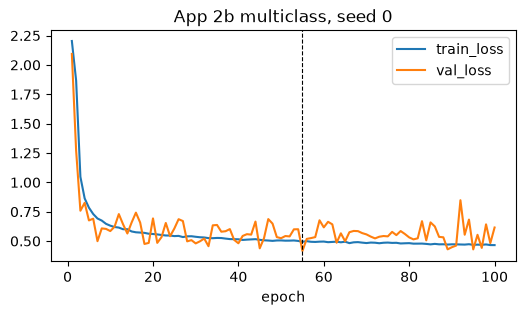

In [8]:
model, info, hist = train_run('2b', 'multiclass', seed=0, show=True)
res, cm = evaluate(model, '2b', 'multiclass')
print(info)
print(f"Test accuracy: {100 * res['acc']:.2f}%  (bài báo: 94,4 ± 2,2%)")
print('Recall từng lớp:', {c: round(100 * res[f'recall_{c}'], 1) for c in CLASSES})
print(f"Phase 1 multiclass (50 lần chạy) ước tính ~{info['seconds'] * 50 / 3600:.1f} giờ")
ax = hist.plot(x='epoch', y=['train_loss', 'val_loss'], figsize=(6, 3), title='App 2b multiclass, seed 0')
ax.axvline(info['best_epoch'], color='k', ls='--', lw=0.8);

So sánh 5 cách tiếp cận trong bài báo 

In [9]:
SEEDS = list(range(10))
TASKS = ['binary', 'multiclass']

def read_runs(file: Path) -> pd.DataFrame:
    if not file.exists():
        return pd.DataFrame(columns=['task', 'approach', 'seed', 'cap'])
    return pd.DataFrame([json.loads(l) for l in file.read_text(encoding='utf-8').splitlines() if l.strip()])

def run_grid(file: Path, configs: list, model_kw=None):
    """Mỗi lần chạy ghi một dòng JSON vào `file` (binary và multiclass có các cột khác nhau)."""
    key = lambda d: (d['task'], str(d['approach']), int(d['seed']), int(d['cap']))
    done = {key(r) for r in read_runs(file).to_dict('records')}
    todo = [c for c in configs if key(c) not in done]
    print(f'{len(configs) - len(todo)} lần đã xong, còn {len(todo)} lần')
    for cfg in tqdm(todo, desc=file.stem):
        model, info, _ = train_run(cfg['approach'], cfg['task'], cfg['seed'], cap=cfg['cap'], model_kw=model_kw)
        res, cm = evaluate(model, cfg['approach'], cfg['task'])
        with open(file, 'a', encoding='utf-8') as fh:
            fh.write(json.dumps({**cfg, **info, **res}) + '\n')
        np.save(RUNS / f"cm_{file.stem}_{cfg['task']}_{cfg['approach']}_cap{cfg['cap']}_s{cfg['seed']}.npy", cm)
    return read_runs(file)

P1 = run_grid(RUNS / 'phase1.jsonl', [dict(task=t, approach=a, seed=s, cap=HP[t]['cap'])
                                    for t in TASKS for a in APPROACHES for s in SEEDS])

0 lần đã xong, còn 100 lần


phase1:   0%|          | 0/100 [00:00<?, ?it/s]

Bảng kết quả so sánh

In [10]:
PAPER_ACC = {'binary':     {'1': 51.8, '2': 98.1, '2b': 98.6, '3': 93.7, '3b': 98.6},
             'multiclass': {'1': 45.5, '2': 87.6, '2b': 94.4, '3': 84.6, '3b': 94.5}}

def summarize(df, metric='acc'):
    g = df.groupby(['task', 'approach'])[metric]
    out = (100 * g.agg(['mean', 'std'])).join(g.size().rename('n'))
    half = stats.t.ppf(0.975, (out.n - 1).clip(lower=1)) * out['std'] / np.sqrt(out.n)
    out['ci95'] = [f'[{m - h:.1f}, {m + h:.1f}]' for m, h in zip(out['mean'], half.fillna(0))]
    out['paper'] = [PAPER_ACC.get(t, {}).get(a) for t, a in out.index]
    return out.round(2)

def welch_vs(df, task, ref='2b', metric='acc'):
    a = df[(df.task == task) & (df.approach == ref)][metric]
    rows = []
    for ap in APPROACHES:
        if ap == ref:
            continue
        b = df[(df.task == task) & (df.approach == ap)][metric]
        p = stats.ttest_ind(a, b, equal_var=False).pvalue if min(len(a), len(b)) > 1 else np.nan
        rows.append(dict(task=task, compare=f'{ref} vs {ap}', diff_pp=round(100 * (a.mean() - b.mean()), 2), p_value=p))
    return pd.DataFrame(rows)

display(summarize(P1))
display(pd.concat([welch_vs(P1, t) for t in TASKS], ignore_index=True))
b = P1[P1.task == 'binary'].groupby('approach')[['attack_precision', 'attack_recall', 'normal_recall']].mean()
print('Binary: attack precision/recall trung bình (bài báo: App 1 có attack precision 10,5%)')
(100 * b).round(2)

mean   std   n          ci95  paper
task       approach                                      
binary     1         52.56  0.61  10  [52.1, 53.0]   51.8
           2         98.29  0.14  10  [98.2, 98.4]   98.1
           2b        98.98  0.01  10  [99.0, 99.0]   98.6
           3         97.49  2.75  10  [95.5, 99.5]   93.7
           3b        98.97  0.02  10  [99.0, 99.0]   98.6
multiclass 1         34.51  7.67  10  [29.0, 40.0]   45.5
           2         73.42  7.89  10  [67.8, 79.1]   87.6
           2b        88.08  3.34  10  [85.7, 90.5]   94.4
           3         73.65  6.89  10  [68.7, 78.6]   84.6
           3b        81.46  4.72  10  [78.1, 84.8]   94.5

,task,compare,diff_pp,p_value
0,binary,2b vs 1,46.41,1.885829e-18
1,binary,2b vs 2,0.69,6.172906e-08
2,binary,2b vs 3,1.49,1.220853e-01
3,binary,2b vs 3b,0.00,5.585910e-01
4,multiclass,2b vs 1,53.57,8.264810e-11
5,multiclass,2b vs 2,14.66,1.506021e-04
6,multiclass,2b vs 3,14.44,4.725270e-05
7,multiclass,2b vs 3b,6.62,2.243860e-03


Binary: attack precision/recall trung bình (bài báo: App 1 có attack precision 10,5%)


,attack_precision,attack_recall,normal_recall
approach,,,
1,11.33,98.55,49.56
2,80.94,94.38,98.54
2b,86.77,98.36,99.02
3,77.02,95.07,97.65
3b,86.74,98.34,99.02


Recall theo từng lớp và Confusion Matrix

,mean_%,std_pp,test_samples,paper_%
Normal,87.39,3.56,1069074,94.1
Brute force,99.95,0.06,67756,100.0
Query flooding,71.79,0.90,1092,95.9
Replay,20.08,6.92,471,7.9
Frame stacking,99.38,0.69,144,99.0
Payload injection,42.52,5.08,218,94.6
Recon,85.70,0.75,200,98.3
FDI,100.00,0.00,5,100.0
Length manipulation,100.00,0.00,50,3.3


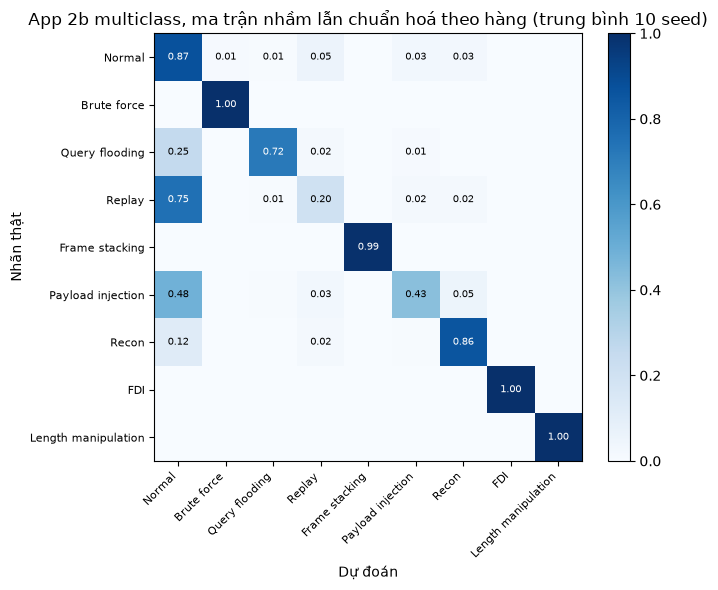

In [11]:
PAPER_RECALL = {'Normal': 94.1, 'Brute force': 100.0, 'Query flooding': 95.9, 'Replay': 7.9, 'Frame stacking': 99.0,
                'Payload injection': 94.6, 'Recon': 98.3, 'FDI': 100.0, 'Length manipulation': 3.3}
m = P1[(P1.task == 'multiclass') & (P1.approach == '2b')]
rc = pd.DataFrame({'mean_%': 100 * m[[f'recall_{c}' for c in CLASSES]].mean().values,
                   'std_pp': 100 * m[[f'recall_{c}' for c in CLASSES]].std().values,
                   'test_samples': np.bincount(LABELS[IDX['test']], minlength=K_MC),
                   'paper_%': [PAPER_RECALL[c] for c in CLASSES]}, index=CLASSES).round(2)
display(rc)

cms = [np.load(f) for f in sorted(RUNS.glob('cm_phase1_multiclass_2b_cap5000_s*.npy'))]
cmn = np.mean([c / np.maximum(c.sum(1, keepdims=True), 1) for c in cms], axis=0)
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(K_MC)); ax.set_xticklabels(CLASSES, rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(K_MC)); ax.set_yticklabels(CLASSES, fontsize=8)
for i in range(K_MC):
    for j in range(K_MC):
        if cmn[i, j] >= 0.005:
            ax.text(j, i, f'{cmn[i, j]:.2f}', ha='center', va='center', fontsize=7,
                    color='white' if cmn[i, j] > 0.5 else 'black')
ax.set_xlabel('Dự đoán'); ax.set_ylabel('Nhãn thật')
ax.set_title(f'App 2b multiclass, ma trận nhầm lẫn chuẩn hoá theo hàng (trung bình {len(cms)} seed)')
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

In [12]:
MODELS = WORK_DIR / 'models'
MODELS.mkdir(parents=True, exist_ok=True)

def save_model(model, path, task, approach, seed, info, res, model_kw=None):
    torch.save({'state_dict': model.state_dict(), 'task': task, 'approach': approach, 'seed': seed,
                'bytes': APPROACHES[approach]['bytes'], 'shape': APPROACHES[approach]['shape'],
                'classes': CLASSES if task == 'multiclass' else ['Normal', 'Attack'],
                'model_kw': model_kw or {}, 'hp': HP[task], 'train_info': info, 'test': res}, path)

def load_model(path):
    ck = torch.load(path, map_location=DEVICE)
    model = make_model(ck['task'], ck['approach'], **ck['model_kw']).to(DEVICE)
    model.load_state_dict(ck['state_dict'])
    return model.eval(), ck

SAVE_APPROACHES = list(APPROACHES)
P1 = read_runs(RUNS / 'phase1.jsonl')
pick = P1.loc[P1.groupby(['task', 'approach'])['best_val_loss'].idxmin()]
pick = pick[pick.approach.astype(str).isin(SAVE_APPROACHES)]

rows = []
for r in tqdm(list(pick.itertuples()), desc='lưu model'):
    task, ap, seed = r.task, str(r.approach), int(r.seed)
    path = MODELS / f'{task}_{ap}_s{seed}.pt'
    if not path.exists():
        model, info, _ = train_run(ap, task, seed)
        res, _ = evaluate(model, ap, task)
        save_model(model, path, task, ap, seed, info, res)
    model, ck = load_model(path)                 # nạp lại từ file để chắc chắn file dùng được
    res, _ = evaluate(model, ap, task)
    rows.append(dict(task=task, approach=ap, seed=seed, val_loss=r.best_val_loss,
                     acc_phase1=100 * r.acc, acc_saved=100 * res['acc'], file=path.name))
pd.DataFrame(rows).round(2)

lưu model:   0%|          | 0/10 [00:00<?, ?it/s]

,task,approach,seed,val_loss,acc_phase1,acc_saved,file
0,binary,1,7,0.42,53.21,53.21,binary_1_s7.pt
1,binary,2,7,0.11,98.21,98.21,binary_2_s7.pt
2,binary,2b,9,0.07,98.99,98.99,binary_2b_s9.pt
3,binary,3,9,0.08,98.72,98.72,binary_3_s9.pt
4,binary,3b,1,0.07,98.95,98.95,binary_3b_s1.pt
5,multiclass,1,2,1.46,41.37,40.89,multiclass_1_s2.pt
6,multiclass,2,0,0.61,61.47,61.47,multiclass_2_s0.pt
7,multiclass,2b,3,0.41,89.20,89.20,multiclass_2b_s3.pt
8,multiclass,3,8,0.68,70.44,70.37,multiclass_3_s8.pt
9,multiclass,3b,8,0.47,84.20,84.01,multiclass_3b_s8.pt
